In [1]:
!pip install -q -U tensorflow kaggle matplotlib scikit-learn pillow
print("Setup complete.")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
Setup complete.


In [2]:
import os
import getpass

os.environ['KAGGLE_API_TOKEN'] = getpass.getpass("Paste your Kaggle API token: ")
print("Kaggle API token configured.")

Paste your Kaggle API token: ··········
Kaggle API token configured.


In [3]:
!kaggle datasets download -d kmader/skin-cancer-mnist-ham10000 -p /content/data --unzip
print("Dataset downloaded to /content/data")

Dataset URL: https://www.kaggle.com/datasets/kmader/skin-cancer-mnist-ham10000
License(s): CC-BY-NC-SA-4.0
100% 5.20G/5.20G [01:02<00:00, 89.5MB/s]

Dataset downloaded to /content/data


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.model_selection import train_test_split

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 10
DATA_DIR = "/content/data"
MODEL_SAVE_PATH = "/content/wound_model.h5"

print("Config set. Image size:", IMG_SIZE)

Config set. Image size: (224, 224)


In [5]:
metadata = pd.read_csv(f"{DATA_DIR}/HAM10000_metadata.csv")

lesion_type_map = {
    'nv': 'Melanocytic_nevi',
    'mel': 'Melanoma',
    'bkl': 'Benign_keratosis',
    'bcc': 'Basal_cell_carcinoma',
    'akiec': 'Actinic_keratoses',
    'vasc': 'Vascular_lesion',
    'df': 'Dermatofibroma'
}
metadata['label'] = metadata['dx'].map(lesion_type_map)

image_paths = {}
for folder in ['HAM10000_images_part_1', 'HAM10000_images_part_2']:
    folder_path = Path(DATA_DIR) / folder
    if folder_path.exists():
        for img_path in folder_path.glob("*.jpg"):
            image_paths[img_path.stem] = str(img_path)

metadata['path'] = metadata['image_id'].map(image_paths.get)
metadata = metadata.dropna(subset=['path'])

print(f"Total usable images: {len(metadata)}")
print(metadata['label'].value_counts())

train_df, val_df = train_test_split(
    metadata, test_size=0.2, stratify=metadata['label'], random_state=42
)
print(f"Train: {len(train_df)}, Validation: {len(val_df)}")

Total usable images: 10015
label
Melanocytic_nevi        6705
Melanoma                1113
Benign_keratosis        1099
Basal_cell_carcinoma     514
Actinic_keratoses        327
Vascular_lesion          142
Dermatofibroma           115
Name: count, dtype: int64
Train: 8012, Validation: 2003


In [6]:
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=20,
    horizontal_flip=True,
    zoom_range=0.1
)
val_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

train_gen = train_datagen.flow_from_dataframe(
    train_df, x_col='path', y_col='label',
    target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode='categorical'
)
val_gen = val_datagen.flow_from_dataframe(
    val_df, x_col='path', y_col='label',
    target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode='categorical', shuffle=False
)

CLASS_NAMES = list(train_gen.class_indices.keys())
NUM_CLASSES = len(CLASS_NAMES)
print("Classes:", CLASS_NAMES)

Found 8012 validated image filenames belonging to 7 classes.
Found 2003 validated image filenames belonging to 7 classes.
Classes: ['Actinic_keratoses', 'Basal_cell_carcinoma', 'Benign_keratosis', 'Dermatofibroma', 'Melanocytic_nevi', 'Melanoma', 'Vascular_lesion']


In [7]:
base_model = MobileNetV2(input_shape=IMG_SIZE + (3,), include_top=False, weights='imagenet')
base_model.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x)
predictions = Dense(NUM_CLASSES, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=predictions)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,422,855 (9.24 MB)

 Trainable params: 164,871 (644.03 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [8]:
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS
)

Epoch 1/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 244s 874ms/step - accuracy: 0.7014 - loss: 0.8597 - val_accuracy: 0.7334 - val_loss: 0.7249
Epoch 2/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 168s 669ms/step - accuracy: 0.7410 - loss: 0.7184 - val_accuracy: 0.7344 - val_loss: 0.7234
Epoch 3/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 167s 667ms/step - accuracy: 0.7599 - loss: 0.6749 - val_accuracy: 0.7668 - val_loss: 0.6487
Epoch 4/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 195s 636ms/step - accuracy: 0.7637 - loss: 0.6565 - val_accuracy: 0.7539 - val_loss: 0.6920
Epoch 5/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 162s 646ms/step - accuracy: 0.7681 - loss: 0.6309 - val_accuracy: 0.7708 - val_loss: 0.6460
Epoch 6/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 162s 644ms/step - accuracy: 0.7765 - loss: 0.6118 - val_accuracy: 0.7469 - val_loss: 0.6782
Epoch 7/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 161s 641ms/step - accuracy: 0.7796 - loss: 0.5940 - val_accuracy: 0.7639 - val_loss: 0.6422
Epoch 8/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 154s 612ms/step - accuracy: 0.7874 -

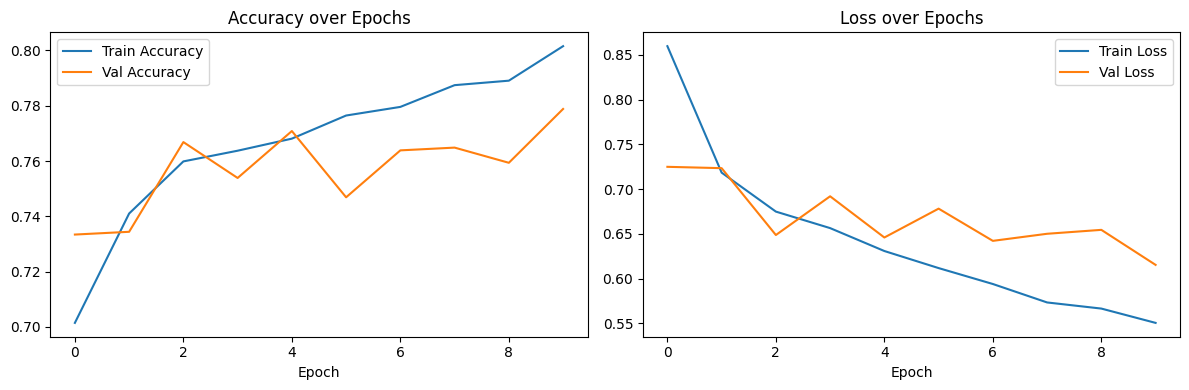

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(history.history['accuracy'], label='Train Accuracy')
ax[0].plot(history.history['val_accuracy'], label='Val Accuracy')
ax[0].set_title('Accuracy over Epochs')
ax[0].set_xlabel('Epoch')
ax[0].legend()

ax[1].plot(history.history['loss'], label='Train Loss')
ax[1].plot(history.history['val_loss'], label='Val Loss')
ax[1].set_title('Loss over Epochs')
ax[1].set_xlabel('Epoch')
ax[1].legend()

plt.tight_layout()
plt.savefig('/content/training_curves.png')
plt.show()

In [10]:
model.save(MODEL_SAVE_PATH)
print(f"Model saved to {MODEL_SAVE_PATH}")

Model saved to /content/wound_model.h5


In [11]:
import datetime
import json

class VisionAgent:

    def __init__(self, model, class_names, img_size):
        self.model = model
        self.class_names = class_names
        self.img_size = img_size

    def analyze(self, image_path):
        img = Image.open(image_path).convert('RGB').resize(self.img_size)
        arr = np.array(img)
        arr = preprocess_input(arr)
        arr = np.expand_dims(arr, axis=0)

        preds = self.model.predict(arr, verbose=0)[0]
        top_idx = int(np.argmax(preds))

        result = {
            "label": self.class_names[top_idx],
            "confidence": float(preds[top_idx]),
            "all_scores": {self.class_names[i]: float(preds[i]) for i in range(len(self.class_names))},
            "timestamp": datetime.datetime.now().isoformat()
        }
        return result

class ComparisonAgent:

    def compare(self, new_result, history):
        if not history:
            return {"status": "baseline", "message": "No previous record found. This is the first scan."}

        last = history[-1]
        conf_change = new_result['confidence'] - last['confidence']
        same_label = new_result['label'] == last['label']

        if same_label and conf_change > 0.05:
            status = "worsening"
            message = f"Same condition detected with higher confidence ({conf_change:+.1%}) than last scan — may be progressing."
        elif same_label and conf_change < -0.05:
            status = "improving"
            message = f"Same condition detected but with lower confidence ({conf_change:+.1%}) — may be improving."
        elif not same_label:
            status = "changed"
            message = f"Classification changed from '{last['label']}' to '{new_result['label']}' since last scan."
        else:
            status = "stable"
            message = "No significant change since the last scan."

        return {"status": status, "message": message, "confidence_change": conf_change}

class AdvisoryAgent:

    HIGH_RISK_LABELS = {"Melanoma", "Basal_cell_carcinoma", "Actinic_keratoses"}

    def advise(self, vision_result, comparison_result):
        label = vision_result['label']
        confidence = vision_result['confidence']
        status = comparison_result['status']

        urgency = "LOW"
        advice = "Continue routine monitoring."

        if label in self.HIGH_RISK_LABELS and confidence > 0.6:
            urgency = "HIGH"
            advice = "This pattern is associated with higher-risk lesion types. Please consult a dermatologist promptly."
        elif status == "worsening":
            urgency = "MEDIUM"
            advice = "The condition appears to be progressing compared to your last scan. Consider seeing a doctor soon."
        elif status == "improving":
            urgency = "LOW"
            advice = "The condition appears to be improving. Continue current care routine."

        return {
            "urgency": urgency,
            "advice": advice,
            "based_on": {"label": label, "confidence": round(confidence, 3), "trend": status}
        }

print("Agents defined: VisionAgent, ComparisonAgent, AdvisoryAgent")

Agents defined: VisionAgent, ComparisonAgent, AdvisoryAgent


In [12]:
class WoundMonitoringSystem:

    def __init__(self, model, class_names, img_size):
        self.vision_agent = VisionAgent(model, class_names, img_size)
        self.comparison_agent = ComparisonAgent()
        self.advisory_agent = AdvisoryAgent()
        self.patient_histories = {}

    def run(self, patient_id, image_path):
        history = self.patient_histories.get(patient_id, [])

        vision_result = self.vision_agent.analyze(image_path)
        comparison_result = self.comparison_agent.compare(vision_result, history)
        advisory_result = self.advisory_agent.advise(vision_result, comparison_result)

        history.append(vision_result)
        self.patient_histories[patient_id] = history

        return {
            "patient_id": patient_id,
            "vision": vision_result,
            "comparison": comparison_result,
            "advisory": advisory_result
        }

print("WoundMonitoringSystem orchestrator ready.")

WoundMonitoringSystem orchestrator ready.


In [13]:
trained_model = tf.keras.models.load_model(MODEL_SAVE_PATH)

system = WoundMonitoringSystem(trained_model, CLASS_NAMES, IMG_SIZE)

sample_images = val_df['path'].sample(2, random_state=1).tolist()

print("=== Visit 1 ===")
result1 = system.run(patient_id="patient_001", image_path=sample_images[0])
print(json.dumps(result1, indent=2))

print("\n=== Visit 2 (later date) ===")
result2 = system.run(patient_id="patient_001", image_path=sample_images[1])
print(json.dumps(result2, indent=2))

=== Visit 1 ===
{
  "patient_id": "patient_001",
  "vision": {
    "label": "Melanocytic_nevi",
    "confidence": 0.5818047523498535,
    "all_scores": {
      "Actinic_keratoses": 0.002026284346356988,
      "Basal_cell_carcinoma": 0.00184119853656739,
      "Benign_keratosis": 0.03122859075665474,
      "Dermatofibroma": 0.0018836741801351309,
      "Melanocytic_nevi": 0.5818047523498535,
      "Melanoma": 0.38117876648902893,
      "Vascular_lesion": 3.673632818390615e-05
    },
    "timestamp": "2026-11-15T15:59:03.125266"
  },
  "comparison": {
    "status": "baseline",
    "message": "No previous record found. This is the first scan."
  },
  "advisory": {
    "urgency": "LOW",
    "advice": "Continue routine monitoring.",
    "based_on": {
      "label": "Melanocytic_nevi",
      "confidence": 0.582,
      "trend": "baseline"
    }
  }
}

=== Visit 2 (later date) ===
{
  "patient_id": "patient_001",
  "vision": {
    "label": "Melanocytic_nevi",
    "confidence": 0.99796199798583

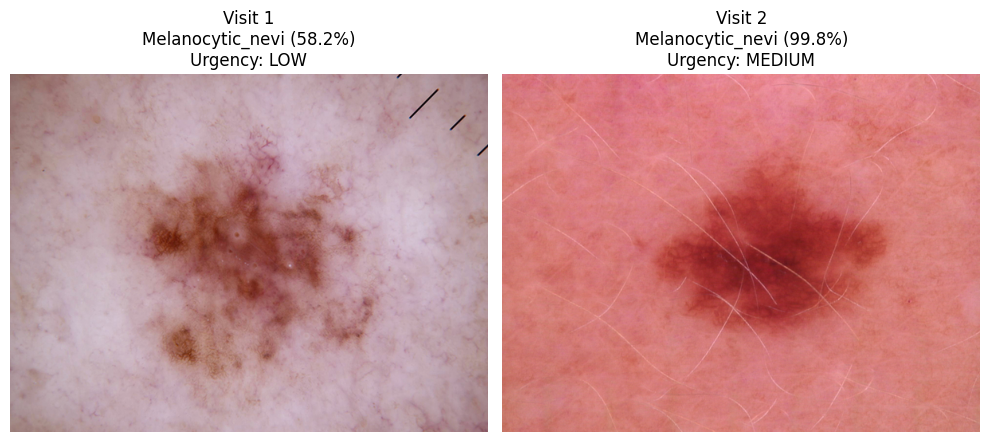

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, path, result, title in zip(
    axes, sample_images, [result1, result2], ["Visit 1", "Visit 2"]
):
    img = Image.open(path)
    ax.imshow(img)
    ax.set_title(f"{title}\n{result['vision']['label']} ({result['vision']['confidence']:.1%})\nUrgency: {result['advisory']['urgency']}")
    ax.axis('off')
plt.tight_layout()
plt.show()